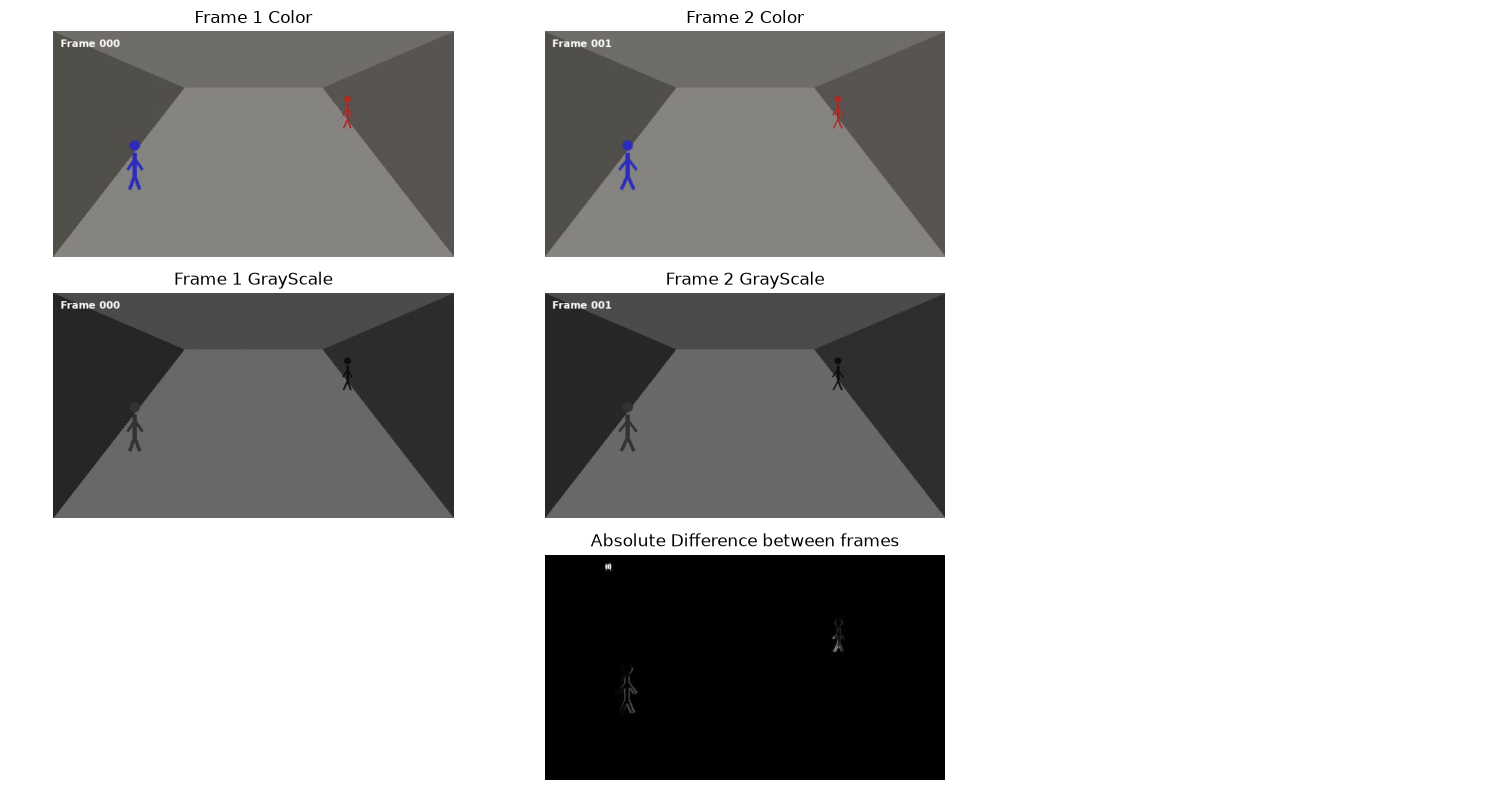

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

video_path = "motion_corridor.avi"
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise FileNotFoundError("Could not open")

ret1, frame1 = cap.read()
ret2, frame2 = cap.read()

cap.release()

if not ret1 or not ret2:
    raise RuntimeError("Failed to read")

frame1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB)
frame2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB)

gray1 = cv2.cvtColor(frame1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_RGB2GRAY)

frame_diff = cv2.absdiff(gray1, gray2)

fig, axes = plt.subplots(3, 3, figsize=(15, 8))

axes[0, 0].imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Frame 1 Color")
axes[0, 0].axis("off")

axes[0, 1].imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title("Frame 2 Color")
axes[0, 1].axis("off")

axes[0, 2].axis("off")

axes[1, 0].imshow(gray1, cmap="gray")
axes[1, 0].set_title("Frame 1 GrayScale")
axes[1, 0].axis("off")

axes[1, 1].imshow(gray2, cmap="gray")
axes[1, 1].set_title("Frame 2 GrayScale")
axes[1, 1].axis("off")

axes[1, 2].axis("off")

axes[2, 0].axis("off")

axes[2, 1].imshow(frame_diff, cmap="gray")
axes[2, 1].set_title("Absolute Difference between frames")
axes[2, 1].axis("off")

axes[2, 2].axis("off")

plt.tight_layout()
plt.show()

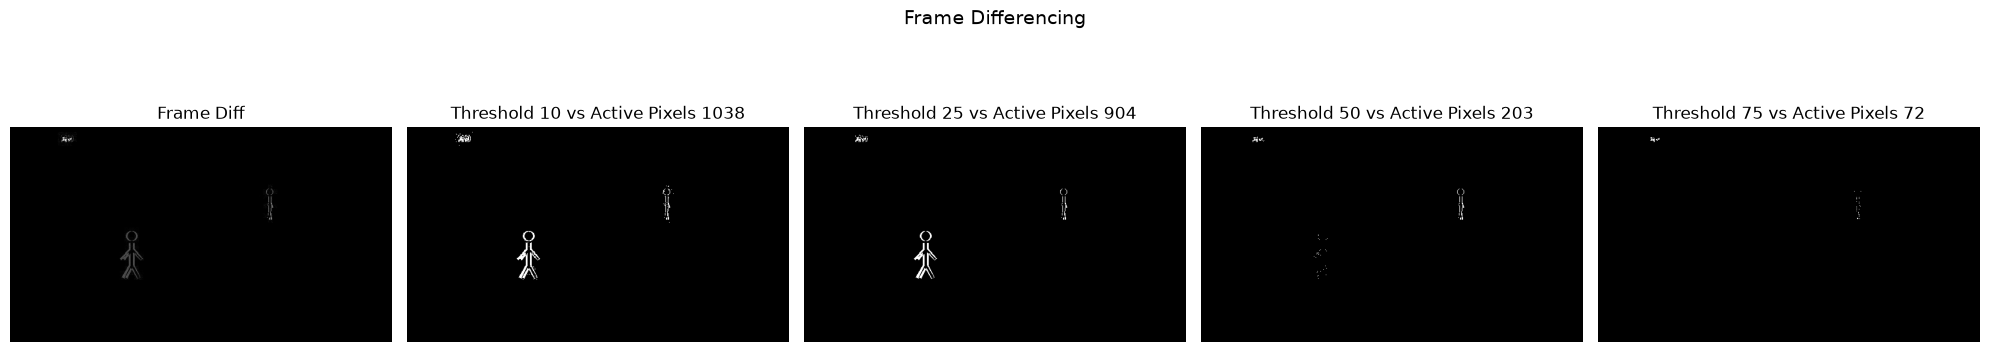

In [8]:
# Frame Differencing

frames = []
cap = cv2.VideoCapture(video_path)
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)

cap.release()

if not frames:
    raise RuntimeError("Failed to read")

idx = 30
prev_gray = cv2.cvtColor(frames[idx-1], cv2.COLOR_BGR2GRAY)
curr_gray = cv2.cvtColor(frames[idx], cv2.COLOR_BGR2GRAY)

diff = cv2.absdiff(prev_gray, curr_gray)

thresholds = [10, 25, 50, 75]
diff_masks = {}
diff_counts = {}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(diff, cmap="gray")
axes[0].set_title("Frame Diff")
axes[0].axis("off")

for i, threshold in enumerate(thresholds):
    _, mask = cv2.threshold(diff, thresh=threshold, maxval=255, type=cv2.THRESH_BINARY)
    diff_masks[threshold] = mask
    diff_counts[threshold] = np.count_nonzero(mask)

    axes[i+1].imshow(mask, cmap="gray")
    axes[i+1].set_title(f"Threshold {threshold} vs Active Pixels {diff_counts[threshold]}")
    axes[i+1].axis("off")

plt.suptitle("Frame Differencing", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

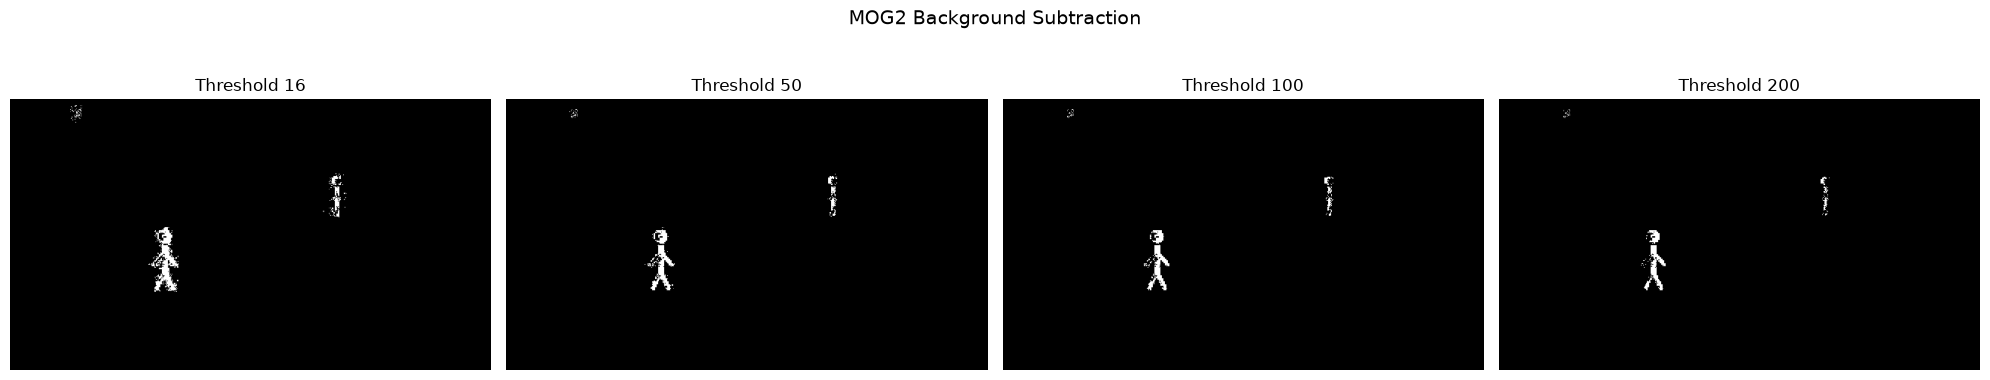

In [10]:
var_thresholds = [16, 50, 100, 200]
mog2_masks = {}
mog2_fg_counts = {}
mog2_shadow_counts = {}

fig, axes = plt.subplots(1, len(var_thresholds), figsize=(20, 4))

for i, var_thresh in enumerate(var_thresholds):
    subtractor = cv2.createBackgroundSubtractorMOG2(history=50, varThreshold=var_thresh, detectShadows=True)

    for f in frames[:idx+1]:
        mask = subtractor.apply(f)

    mog2_masks[var_thresh] = mask

    fg_pixels = np.count_nonzero(mask == 255)
    shadow_pixels = np.count_nonzero(mask == 127)

    mog2_fg_counts[var_thresh] = fg_pixels
    mog2_shadow_counts[var_thresh] = shadow_pixels

    axes[i].imshow(mask, cmap="gray")
    axes[i].set_title(f"Threshold {var_thresh}")
    axes[i].axis("off")

plt.suptitle("MOG2 Background Subtraction", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

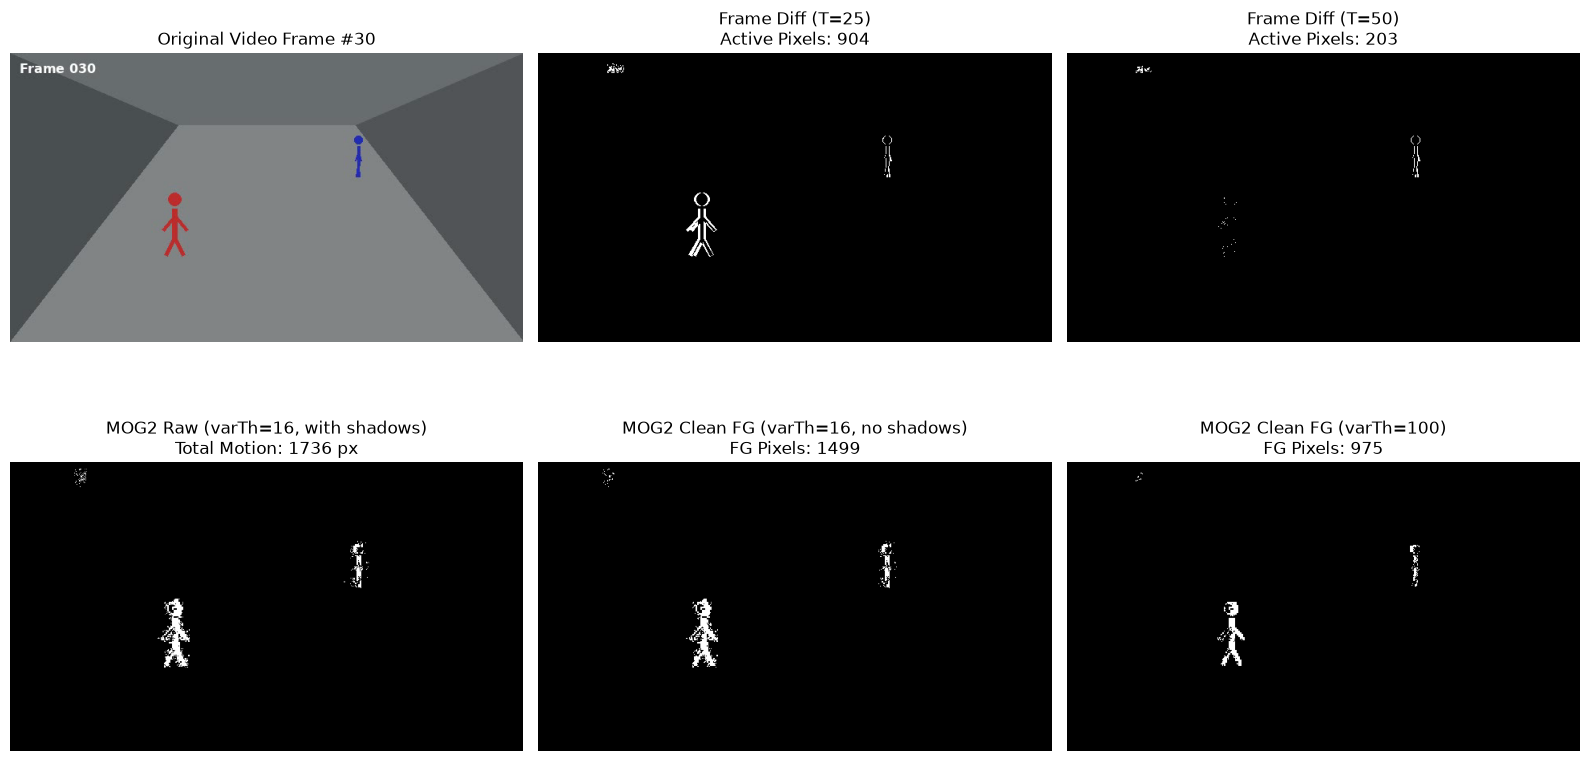

Method                         | Parameter          | Detected FG Pixels
------------------------------------------------------------------------
Frame Differencing             | T = 10             | 1038              
Frame Differencing             | T = 25             | 904               
Frame Differencing             | T = 50             | 203               
Frame Differencing             | T = 75             | 72                
------------------------------------------------------------------------
MOG2 (Strict Foreground)       | varThreshold = 16  | 1499              
MOG2 (Strict Foreground)       | varThreshold = 50  | 1086              
MOG2 (Strict Foreground)       | varThreshold = 100 | 975               
MOG2 (Strict Foreground)       | varThreshold = 200 | 856               


In [11]:
# Extract clean binary foreground masks (excluding shadows from MOG2)
mog2_clean_16 = (mog2_masks[16] == 255).astype(np.uint8) * 255
mog2_clean_100 = (mog2_masks[100] == 255).astype(np.uint8) * 255

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Original Color Frame
axes[0, 0].imshow(cv2.cvtColor(frames[idx], cv2.COLOR_BGR2RGB))
axes[0, 0].set_title(f"Original Video Frame #{idx}")
axes[0, 0].axis("off")

# Frame Diff (T=25)
axes[0, 1].imshow(diff_masks[25], cmap="gray")
axes[0, 1].set_title(f"Frame Diff (T=25)\nActive Pixels: {diff_counts[25]}")
axes[0, 1].axis("off")

# Frame Diff (T=50)
axes[0, 2].imshow(diff_masks[50], cmap="gray")
axes[0, 2].set_title(f"Frame Diff (T=50)\nActive Pixels: {diff_counts[50]}")
axes[0, 2].axis("off")

# MOG2 Raw with Shadows (varThreshold=16)
axes[1, 0].imshow(mog2_masks[16], cmap="gray")
axes[1, 0].set_title(f"MOG2 Raw (varTh=16, with shadows)\nTotal Motion: {mog2_fg_counts[16] + mog2_shadow_counts[16]} px")
axes[1, 0].axis("off")

# MOG2 Clean Foreground (varThreshold=16)
axes[1, 1].imshow(mog2_clean_16, cmap="gray")
axes[1, 1].set_title(f"MOG2 Clean FG (varTh=16, no shadows)\nFG Pixels: {mog2_fg_counts[16]}")
axes[1, 1].axis("off")

# MOG2 Clean Foreground (varThreshold=100)
axes[1, 2].imshow(mog2_clean_100, cmap="gray")
axes[1, 2].set_title(f"MOG2 Clean FG (varTh=100)\nFG Pixels: {mog2_fg_counts[100]}")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

# Quantitative summary table
print(f"{'Method':<30} | {'Parameter':<18} | {'Detected FG Pixels':<18}")
print("-" * 72)
for T in thresholds:
    print(f"{'Frame Differencing':<30} | {f'T = {T}':<18} | {diff_counts[T]:<18}")
print("-" * 72)
for vt in var_thresholds:
    print(f"{'MOG2 (Strict Foreground)':<30} | {f'varThreshold = {vt}':<18} | {mog2_fg_counts[vt]:<18}")


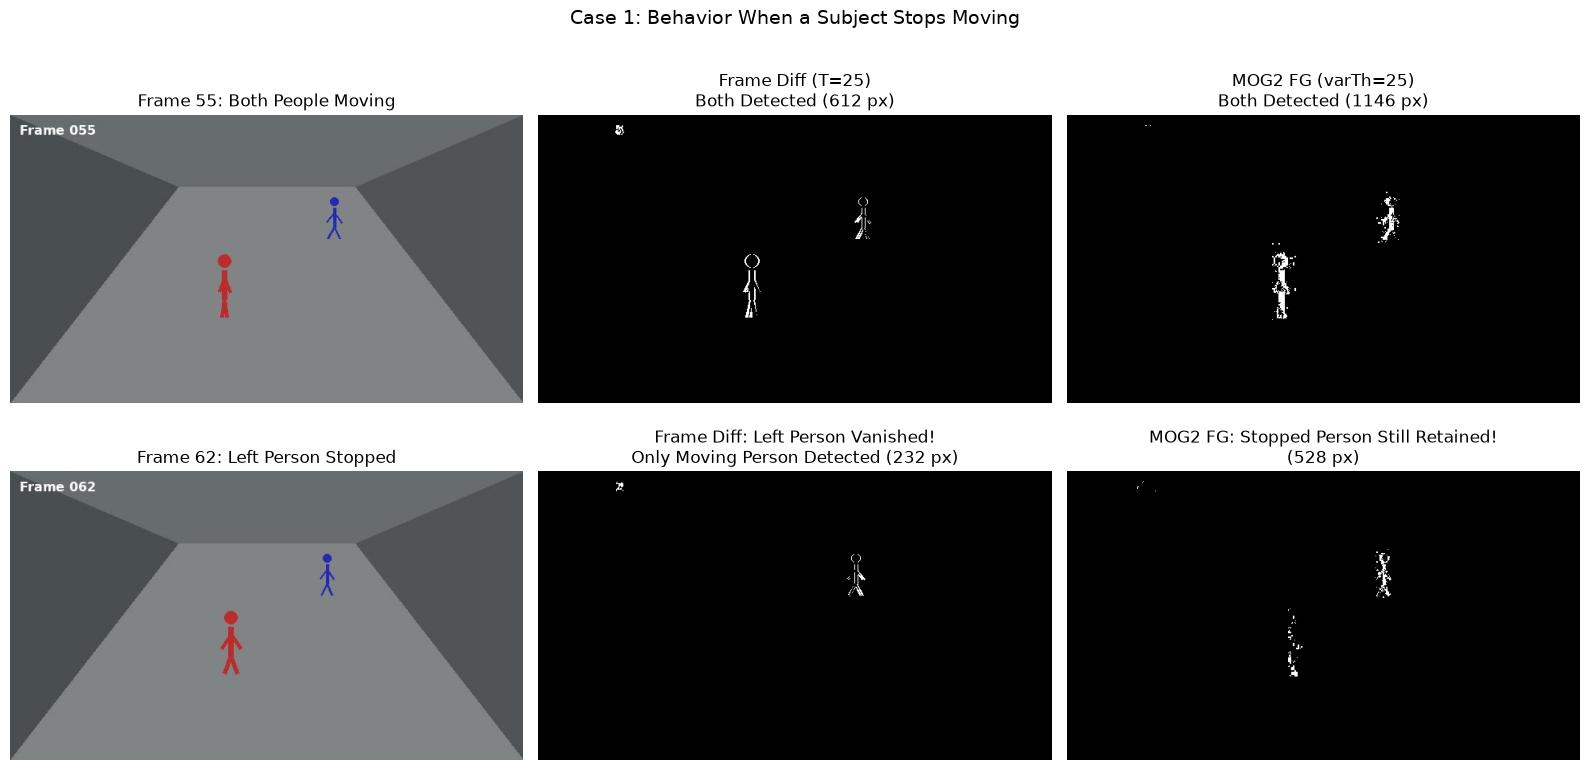

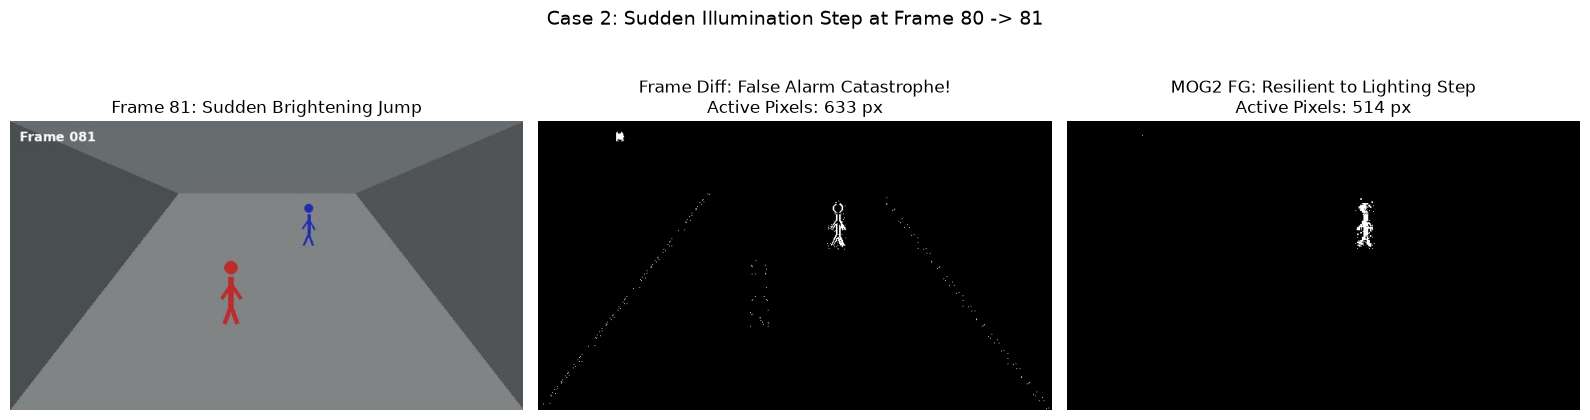

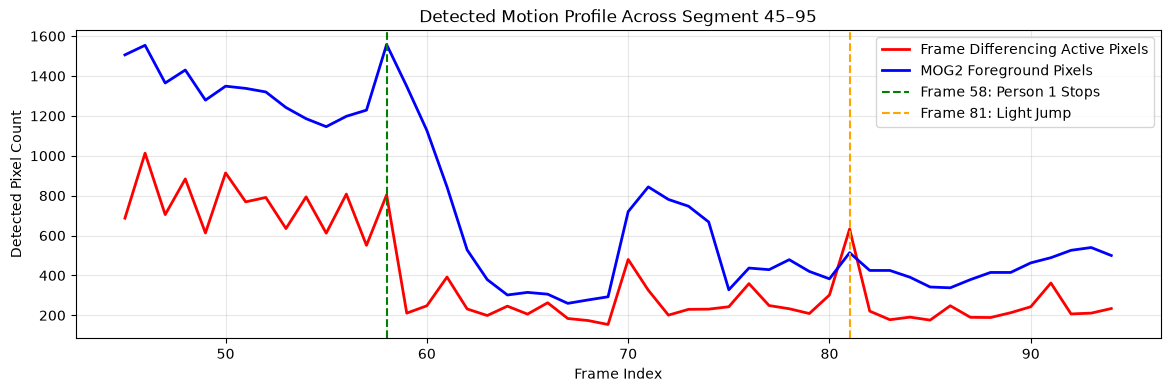

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load video frames
cap = cv2.VideoCapture("motion_corridor.avi")
frames = []
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)
cap.release()

# 2. Run MOG2 across the video up to frame 95
mog2 = cv2.createBackgroundSubtractorMOG2(history=50, varThreshold=25, detectShadows=True)
mog2_masks = [mog2.apply(f) for f in frames]

# Helper to compute binary frame difference
def get_frame_diff(f_prev, f_curr, thresh=25):
    g_prev = cv2.cvtColor(f_prev, cv2.COLOR_BGR2GRAY)
    g_curr = cv2.cvtColor(f_curr, cv2.COLOR_BGR2GRAY)
    d = cv2.absdiff(g_prev, g_curr)
    _, mask = cv2.threshold(d, thresh, 255, cv2.THRESH_BINARY)
    return mask

# =========================================================================
# EXPERIMENT 1: Person Stops (Frame 55: Both Moving vs Frame 62: Person 1 Stopped)
# =========================================================================
diff_55 = get_frame_diff(frames[54], frames[55])
diff_62 = get_frame_diff(frames[61], frames[62])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Frame 55 (Both moving)
axes[0, 0].imshow(cv2.cvtColor(frames[55], cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Frame 55: Both People Moving")
axes[0, 0].axis("off")

axes[0, 1].imshow(diff_55, cmap="gray")
axes[0, 1].set_title(f"Frame Diff (T=25)\nBoth Detected ({np.count_nonzero(diff_55)} px)")
axes[0, 1].axis("off")

axes[0, 2].imshow(mog2_masks[55] == 255, cmap="gray")
axes[0, 2].set_title(f"MOG2 FG (varTh=25)\nBoth Detected ({np.count_nonzero(mog2_masks[55] == 255)} px)")
axes[0, 2].axis("off")

# Frame 62 (Person 1 has stopped, Person 2 moving)
axes[1, 0].imshow(cv2.cvtColor(frames[62], cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("Frame 62: Left Person Stopped")
axes[1, 0].axis("off")

axes[1, 1].imshow(diff_62, cmap="gray")
axes[1, 1].set_title(f"Frame Diff: Left Person Vanished!\nOnly Moving Person Detected ({np.count_nonzero(diff_62)} px)")
axes[1, 1].axis("off")

axes[1, 2].imshow(mog2_masks[62] == 255, cmap="gray")
axes[1, 2].set_title(f"MOG2 FG: Stopped Person Still Retained!\n({np.count_nonzero(mog2_masks[62] == 255)} px)")
axes[1, 2].axis("off")

plt.suptitle("Case 1: Behavior When a Subject Stops Moving", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# =========================================================================
# EXPERIMENT 2: Sudden Illumination Change (Frame 80 -> 81)
# =========================================================================
diff_81 = get_frame_diff(frames[80], frames[81])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].imshow(cv2.cvtColor(frames[81], cv2.COLOR_BGR2RGB))
axes[0].set_title("Frame 81: Sudden Brightening Jump")
axes[0].axis("off")

axes[1].imshow(diff_81, cmap="gray")
axes[1].set_title(f"Frame Diff: False Alarm Catastrophe!\nActive Pixels: {np.count_nonzero(diff_81)} px")
axes[1].axis("off")

axes[2].imshow(mog2_masks[81] == 255, cmap="gray")
axes[2].set_title(f"MOG2 FG: Resilient to Lighting Step\nActive Pixels: {np.count_nonzero(mog2_masks[81] == 255)} px")
axes[2].axis("off")

plt.suptitle("Case 2: Sudden Illumination Step at Frame 80 -> 81", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

# =========================================================================
# EXPERIMENT 3: Temporal Motion Profile (Frames 45 to 95)
# =========================================================================
frame_diff_totals = [np.count_nonzero(get_frame_diff(frames[i - 1], frames[i])) for i in range(1, len(frames))]
mog2_totals = [np.count_nonzero(m == 255) for m in mog2_masks[1:]]

plt.figure(figsize=(14, 4))
plt.plot(range(45, 95), frame_diff_totals[44:94], label="Frame Differencing Active Pixels", color="red", linewidth=2)
plt.plot(range(45, 95), mog2_totals[44:94], label="MOG2 Foreground Pixels", color="blue", linewidth=2)
plt.axvline(x=58, color="green", linestyle="--", label="Frame 58: Person 1 Stops")
plt.axvline(x=81, color="orange", linestyle="--", label="Frame 81: Light Jump")
plt.title("Detected Motion Profile Across Segment 45–95")
plt.xlabel("Frame Index")
plt.ylabel("Detected Pixel Count")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
